# 01 — Data collection and exploration
**CSC17104 Final Project — DDR5 and NVMe prices in 12 U.S. ZIP markets (2026)**

Team: Chung Nguyên (Q1, Q2) · Minh Trí (Q3, Q4) · Đức Khải (Q5, Q6)

This notebook covers sections **3.1 Data collection** and **3.2 Data exploration** of the project brief.
Sections marked `TODO (team)` must be written by the team in its own words after looking at the outputs.

**How to run:** from the repository root, `conda activate ddr5-nvme`, run `python src/fetch_data.py`, then run this notebook top to bottom.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make `src` importable whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))   # the repo root, NOT src/ (src/io.py would shadow the stdlib `io`)

from src.io import load_raw, validate_raw, print_validation, save_processed, KEEP_COLUMNS, DROPPED_COLUMNS
from src.cleaning import (RowLog, add_flags, check_normalized_price,
                          flag_outliers_iqr, basic_quality_report)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 3.1 Data collection

| Item | Answer |
|---|---|
| **Subject** | Listed prices of DDR5 memory kits and NVMe SSDs, observed daily in 12 U.S. ZIP-code markets. One row = one dated product-price observation in its category and ZIP market. |
| **Source** | Kaggle: <https://www.kaggle.com/datasets/costinflation/ddr5-and-nvme-prices-raw-dataset-2026>. Owner: CostInflation Team. Static one-time snapshot (update frequency: never). |
| **License** | CC0 1.0 Universal (public domain dedication): no attribution required, no restrictions. We still cite the source. |
| **Period / coverage** | 2026-07-21 to 2026-08-18 (29 dates), 12 ZIP markets, 127,843 rows: 18,650 DDR5 and 109,193 NVMe. |
| **Collection method** | TODO (team): the data card only says the values are *recorded* observations of listed prices. Write what is known (listing prices, not transactions; product names are not unique SKUs) and state clearly what is **not** documented (retailers, scraping method, how ZIP affects the listing). |
| **Known limitations** | 4,357 rows with unresolved capacity (blank normalized price); 17 complete laptop/desktop/mini-PC rows inside DDR5 (data card; all unresolved capacity) plus 11 complete NAS-appliance rows (found by us; capacity *resolved* as 16 GB, so they are not in the data card count); 83,810 names contain pack/count wording; only 29 days, only 12 ZIPs; raw values, nothing corrected. Normalization targets differ (1 GB for DDR5, 1 TB for NVMe), so DDR5 and NVMe prices per unit are **not** comparable. |
| **Existing public work** | TODO (team): the Kaggle Code tab showed 0 notebooks when the dataset was chosen. Re-check the date and put a screenshot in `docs/kaggle_code_tab.png`. |
| **Motivation** | TODO (team): why did the group choose this dataset? |

## 3.2 Data exploration

### 3.2.1 Overview — structure and what one row represents

In [2]:
RAW_ALL = load_raw(columns="all", validate=False)      # all 16 columns, for the overview only
print("Shape (all columns):", RAW_ALL.shape)
RAW_ALL.head(5)

Shape (all columns): (127843, 16)


,series_id,series_title,canonical_url,geography_type,geography_id,geography_label,observed_date,product_name,quantity_value,quantity_unit,quantity_name,price_amount,currency_code,normalized_price_amount,normalized_quantity_value,normalized_quantity_unit
0,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-price-per-gb,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-21,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM 1.1V Non-ECC Unbuffered SO-DIMM 262-Pin...,16.0000,gigabytes,16 gigabytes,242.4800,USD,15.1550,1.0000,gigabytes
1,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-price-per-gb,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-21,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 UDIMM 1.1V Non-ECC Unbuffered DIMM 288-Pin Des...,16.0000,gigabytes,16 gigabytes,248.4900,USD,15.5306,1.0000,gigabytes
2,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-price-per-gb,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-21,A-Tech 32GB DDR5 4800MHz PC5-38400 CL40 SODIMM 2Rx8 Dual Rank 1.1V Non-ECC Unbuffered ...,32.0000,gigabytes,32 gigabytes,350.5400,USD,10.9544,1.0000,gigabytes
3,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-price-per-gb,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-21,A-Tech 32GB DDR5 4800MHz PC5-38400 CL40 UDIMM 2Rx8 Dual Rank 1.1V Non-ECC Unbuffered D...,32.0000,gigabytes,32 gigabytes,432.1700,USD,13.5053,1.0000,gigabytes
4,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-price-per-gb,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-21,A-Tech 64GB Kit (2x32GB) DDR5 5600MHz PC5-44800 CL46 SODIMM 2Rx8 Dual Rank 1.1V Non-EC...,64.0000,gigabytes,64 gigabytes,876.9100,USD,13.7017,1.0000,gigabytes


In [3]:
# Which columns carry information? Constant columns are candidates to drop.
overview = pd.DataFrame({
    "dtype": RAW_ALL.dtypes.astype(str),
    "n_unique": RAW_ALL.nunique(dropna=True),
    "n_missing": RAW_ALL.isna().sum(),
    "example": RAW_ALL.iloc[0].astype(str).str.slice(0, 60),
})
overview["decision"] = np.where(overview.index.isin(DROPPED_COLUMNS), "drop", "keep")
overview

,dtype,n_unique,n_missing,example,decision
series_id,category,2,0,ddr5_memory,keep
series_title,str,2,0,DDR5 RAM,drop
canonical_url,str,2,0,https://costinflation.com/indices/ddr5-ram-price-per-gb,drop
geography_type,str,1,0,postal_code,drop
geography_id,string,12,0,11385,keep
geography_label,category,12,0,"New York, NY - Ridgewood/Glendale",keep
observed_date,datetime64[us],29,0,2026-07-21 00:00:00,keep
product_name,string,1176,0,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM 1.1V Non-ECC,keep
quantity_value,float64,25,0,16.0,keep
quantity_unit,category,3,0,gigabytes,keep


**Column decisions (see `DECISIONS.md`).** Six columns are dropped because they are constant or redundant:
`series_title` (same information as `series_id`), `canonical_url` (category info page), `geography_type` (always `postal_code`),
`currency_code` (always `USD`), `normalized_quantity_value` (always 1.000) and `normalized_quantity_unit` (determined by category).
The remaining 10 columns are kept. `normalized_price_amount` is a **function of the price**, so it must never be a feature when predicting `price_amount` (Q6).

In [4]:
log = RowLog()
df = RAW_ALL[KEEP_COLUMNS].copy()
df = log.note(df, "load raw CSV, keep 10 of 16 columns", reason="6 constant/redundant columns removed (columns, not rows)")
print_validation(validate_raw(df))
validate_raw(df)

[load raw CSV, keep 10 of 16 columns] 127,843 -> 127,843 rows (removed 0)
[OK] All 12 checks match the Kaggle data card.


,check,expected,actual,ok
0,n_rows,127843,127843,True
1,rows[ddr5_memory],18650,18650,True
2,rows[nvme_ssd],109193,109193,True
3,n_zip,12,12,True
4,n_dates,29,29,True
5,n_product_names,1176,1176,True
6,date_min,2026-07-21,2026-07-21,True
7,date_max,2026-08-18,2026-08-18,True
8,normalized_nonblank,123486,123486,True
9,normalized_blank,4357,4357,True


In [ ]:
df = add_flags(df)
df = log.note(df, "add flag columns",
              reason="category, is_unresolved, is_system_noise, is_nas_noise, is_noise, price_per_unit_recomputed (no rows removed)")
df[["category", "is_unresolved", "is_system_noise", "is_nas_noise", "is_noise", "price_per_unit_recomputed"]].describe(include="all")

In [ ]:
basic_quality_report(df)

**Duplicates / empty rows.** The checks above show whether any exact duplicate or fully empty row exists.
`TODO (team)`: state the result and the decision (the data card claims zero exact duplicates; confirm it).
Note that repeated `(product_name, ZIP, date)` combinations are **not** duplicates (several listings can share a title); we measure this in 3.2.7.

### 3.2.2 Numerical columns

In [7]:
pcts = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
df.groupby("category", observed=True)["price_amount"].describe(percentiles=pcts).T

category,DDR5,NVMe
count,"18,650.0000","109,193.0000"
mean,790.9127,220.9529
std,992.7112,166.9493
min,109.9900,27.3500
1%,129.8600,39.9900
5%,212.9900,50.4000
25%,399.9900,99.9900
50%,479.9900,169.9900
75%,828.9900,289.0000
95%,"3,329.9900",579.9900


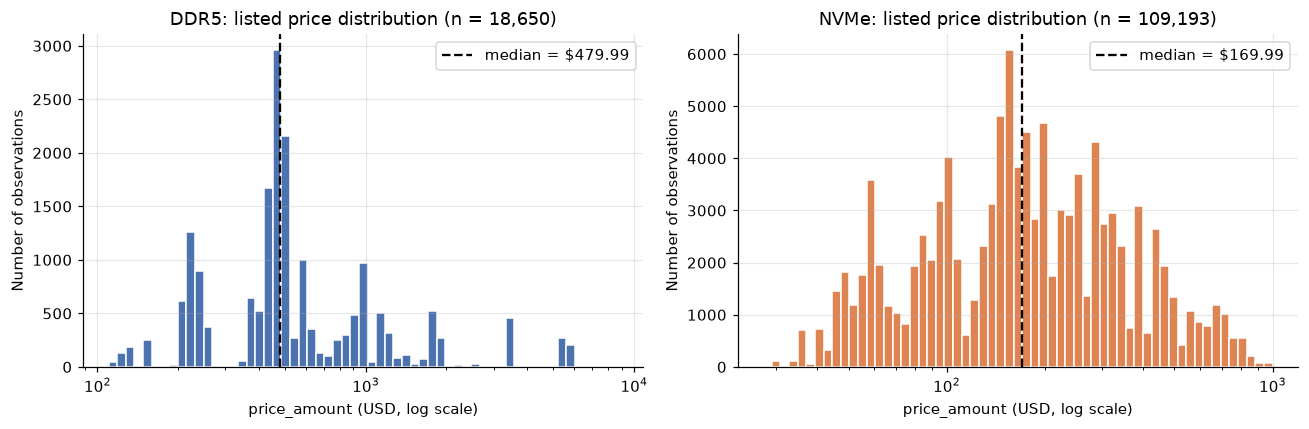

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (cat, g) in zip(axes, df.groupby("category", observed=True)):
    bins = np.logspace(np.log10(g["price_amount"].min()), np.log10(g["price_amount"].max()), 60)
    ax.hist(g["price_amount"], bins=bins, color="#4C72B0" if cat == "DDR5" else "#DD8452", edgecolor="white")
    ax.set_xscale("log")
    ax.axvline(g["price_amount"].median(), color="black", ls="--", label=f"median = ${g['price_amount'].median():,.2f}")
    ax.set_title(f"{cat}: listed price distribution (n = {len(g):,})")
    ax.set_xlabel("price_amount (USD, log scale)")
    ax.set_ylabel("Number of observations")
    ax.legend()
plt.tight_layout(); plt.show()

Prices are right-skewed (a log axis is needed to see the bulk), so we expect to use **medians, IQR and log-price** rather than plain means.
`TODO (team)`: describe the shape, centre and spread of each category in 1–2 sentences, using the numbers above.

In [9]:
# Outliers: IQR rule on log(price), computed WITHIN each category (DDR5 and NVMe are never compared to each other).
rows = []
for k in (1.5, 3.0):
    flag = flag_outliers_iqr(df, "price_amount", by="category", k=k, use_log=True)
    for cat in ("DDR5", "NVMe"):
        m = df["category"] == cat
        rows.append({"rule": f"IQR x {k} on log(price)", "category": cat,
                     "n_outliers": int(flag[m].sum()), "pct": 100 * flag[m].mean()})
pd.DataFrame(rows)

,rule,category,n_outliers,pct
0,IQR x 1.5 on log(price),DDR5,1315,7.0509
1,IQR x 1.5 on log(price),NVMe,0,0.0000
2,IQR x 3.0 on log(price),DDR5,2,0.0107
3,IQR x 3.0 on log(price),NVMe,0,0.0000


In [10]:
# Are the extremes genuine or errors? Look at the cheapest and most expensive rows.
cols = ["category", "product_name", "quantity_value", "quantity_unit", "price_amount", "geography_id", "observed_date"]
for cat in ("DDR5", "NVMe"):
    g = df[df["category"] == cat]
    print(f"===== {cat}: 8 cheapest =====")
    display(g.nsmallest(8, "price_amount")[cols])
    print(f"===== {cat}: 8 most expensive =====")
    display(g.nlargest(8, "price_amount")[cols])

===== DDR5: 8 cheapest =====


,category,product_name,quantity_value,quantity_unit,price_amount,geography_id,observed_date
646,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,11385,2026-07-31
767,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,11385,2026-08-02
828,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,11385,2026-08-03
872,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,11385,2026-08-04
2199,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,19145,2026-07-31
2257,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,19145,2026-08-01
2321,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,19145,2026-08-02
2382,DDR5,PNY DDR5 8GB (1x8GB) 5600MHz CL46 Performance Desktop Memory | Not Intel 15th Gen Comp...,8.0000,gigabytes,109.9900,19145,2026-08-03


===== DDR5: 8 most expensive =====


,category,product_name,quantity_value,quantity_unit,price_amount,geography_id,observed_date
1062,DDR5,V-Color DDR5 256GB (64GBx4) 6400MHz CL60 ECC R-DIMM (ECC Registered DIMM) 1.1V Memory ...,256.0000,gigabytes,"8,719.9900",11385,2026-08-08
1210,DDR5,V-Color DDR5 256GB (64GBx4) 6400MHz CL60 ECC R-DIMM (ECC Registered DIMM) 1.1V Memory ...,256.0000,gigabytes,"8,719.9900",11385,2026-08-11
117,DDR5,V-Color DDR5 256GB (64GBx4) 4800MHz CL46 ECC R-DIMM (ECC Registered DIMM) 1.1V Memory ...,256.0000,gigabytes,"6,599.9900",11385,2026-07-22
1085,DDR5,G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 256GB (4x64GB) 6000MT/s CL36-44-...,256.0000,gigabytes,"5,999.9900",11385,2026-08-09
1134,DDR5,G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 256GB (4x64GB) 6000MT/s CL36-44-...,256.0000,gigabytes,"5,999.9900",11385,2026-08-10
1186,DDR5,G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 256GB (4x64GB) 6000MT/s CL36-44-...,256.0000,gigabytes,"5,999.9900",11385,2026-08-11
1285,DDR5,G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 256GB (4x64GB) 6000MT/s CL36-44-...,256.0000,gigabytes,"5,999.9900",11385,2026-08-13
1380,DDR5,G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 256GB (4x64GB) Up to 6000MT/s CL...,256.0000,gigabytes,"5,999.9900",11385,2026-08-15


===== NVMe: 8 cheapest =====


,category,product_name,quantity_value,quantity_unit,price_amount,geography_id,observed_date
27329,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,11385,2026-08-17
27657,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,11385,2026-08-18
36434,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,19145,2026-08-17
36748,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,19145,2026-08-18
44949,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,32210,2026-08-15
45598,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,32210,2026-08-17
53996,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,39206,2026-08-15
54639,NVMe,Oemgenuine OEM WDC 128GB M.2 PCI-e NVME Internal SN520 Solid State Drive 42mm 2242 For...,128.0000,gigabytes,27.3500,39206,2026-08-17


===== NVMe: 8 most expensive =====


,category,product_name,quantity_value,quantity_unit,price_amount,geography_id,observed_date
19503,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-07-23
19805,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-07-24
21042,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-07-28
22259,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-08-01
22575,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-08-02
22904,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-08-03
23546,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-08-05
23863,NVMe,"Sandisk Optimus GX PRO 4TB 850X NVMe SSD Internal Solid State Drive - Gen4 PCIe, M.2 2...",4.0000,terabytes,999.9900,11385,2026-08-06


`TODO (team)`: for the rows above, decide whether each extreme is plausible (e.g. a 128 GB kit or an 8 TB drive is expensive but genuine) or an error (e.g. a bundle or a mis-categorised product), and write the decision.
Rule of thumb for this project: **do not remove an extreme just because it is extreme**; if it changes a conclusion, report it as a sensitivity check (criterion D6).

In [11]:
# Capacity: placeholder values (quantity_value = 0 / unit 'unknown') are real "unresolved" markers, not capacities.
cap = (df.groupby(["category", "quantity_unit", "quantity_value"], observed=True)
         .size().rename("n_rows").reset_index())
for cat in ("DDR5", "NVMe"):
    print(f"===== {cat}: capacity values, by number of rows =====")
    display(cap[cap["category"] == cat].sort_values("n_rows", ascending=False).head(15).reset_index(drop=True))

===== DDR5: capacity values, by number of rows =====


,category,quantity_unit,quantity_value,n_rows
0,DDR5,gigabytes,32.0000,9607
1,DDR5,gigabytes,16.0000,3206
2,DDR5,gigabytes,64.0000,2965
3,DDR5,gigabytes,128.0000,847
4,DDR5,gigabytes,8.0000,620
5,DDR5,gigabytes,96.0000,576
6,DDR5,gigabytes,256.0000,480
7,DDR5,gigabytes,48.0000,332
8,DDR5,unknown,0.0000,17


===== NVMe: capacity values, by number of rows =====


,category,quantity_unit,quantity_value,n_rows
0,NVMe,terabytes,1.0000,32357
1,NVMe,terabytes,2.0000,20527
2,NVMe,gigabytes,256.0000,16306
3,NVMe,gigabytes,512.0000,15958
4,NVMe,terabytes,4.0000,7929
5,NVMe,gigabytes,500.0000,5867
6,NVMe,gigabytes,128.0000,4351
7,NVMe,unknown,0.0000,4340
8,NVMe,gigabytes,960.0000,627
9,NVMe,gigabytes,"1,000.0000",214


In [12]:
# Normalised price (source-recorded) and our own recomputation from price / capacity.
print(df.groupby("category", observed=True)["normalized_price_amount"].describe(percentiles=[0.05, 0.5, 0.95]).T)
print()
print("Cross-check of normalized_price_amount against price_amount / capacity:")
pd.Series(check_normalized_price(df)).to_frame("value")

category        DDR5         NVMe
count    18,633.0000 104,853.0000
mean         15.7143     221.2271
std           3.6092      93.9609
min          10.2328      36.2650
5%           12.0831     125.4950
50%          14.8436     198.9950
95%          23.3593     399.9800
max         138.3119   1,514.5000

Cross-check of normalized_price_amount against price_amount / capacity:


,value
n_compared,"123,486.0000"
max_abs_diff,0.0000
n_over_tol,0.0000
n_blank_norm_but_resolved,0.0000
n_norm_but_unresolved,0.0000


### 3.2.3 Categorical columns

In [13]:
cat_summary = pd.DataFrame({
    "n_unique": [df["series_id"].nunique(), df["geography_id"].nunique(), df["observed_date"].nunique(),
                 df["product_name"].nunique(), df["quantity_unit"].nunique(), df["quantity_name"].nunique()],
}, index=["series_id", "geography_id", "observed_date", "product_name", "quantity_unit", "quantity_name"])
cat_summary

,n_unique
series_id,2
geography_id,12
observed_date,29
product_name,1176
quantity_unit,3
quantity_name,25


In [14]:
# Rows per ZIP market and category (balance).
zip_tab = pd.crosstab([df["geography_id"], df["geography_label"].astype(str)], df["category"], margins=True)
zip_tab

,category,DDR5,NVMe,All
geography_id,geography_label,,,
11385,"New York, NY - Ridgewood/Glendale",1550,9143,10693
19145,"Philadelphia, PA - South Philadelphia",1592,9089,10681
32210,"Jacksonville, FL - Westside",1505,9177,10682
39206,"Jackson, MS - North Jackson",1577,9041,10618
60618,"Chicago, IL - North Center/Avondale",1553,9067,10620
62201,"East St. Louis, IL",1557,9103,10660
63105,"Clayton, MO",1565,9125,10690
77004,"Houston, TX - Midtown",1564,9120,10684
78228,"San Antonio, TX - West San Antonio",1581,9056,10637


In [15]:
# Product names: consistency of labels (case / extra spaces) and how concentrated the titles are.
norm_name = df["product_name"].astype(str).str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("Distinct raw product_name:", df["product_name"].nunique())
print("Distinct after lowercase + whitespace normalisation:", norm_name.nunique())
print("(identical numbers mean there are no case/space variants of the same title)")
print()
per_title = df.groupby(["category", "product_name"], observed=True).size().rename("n_rows")
print("Rows per title, summary:")
display(per_title.groupby("category", observed=True).describe())
print("Titles with fewer than 20 observations (rare):")
display((per_title < 20).groupby("category", observed=True).agg(n_rare_titles="sum", n_titles="size"))

Distinct raw product_name: 1176
Distinct after lowercase + whitespace normalisation: 1172
(identical numbers mean there are no case/space variants of the same title)

Rows per title, summary:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
DDR5,228.0000,81.7982,104.8446,1.0000,4.0000,30.0000,142.7500,348.0000
NVMe,948.0000,115.1825,112.2041,1.0000,19.7500,74.0000,190.0000,483.0000


Titles with fewer than 20 observations (rare):


,n_rare_titles,n_titles
category,,
DDR5,103,228
NVMe,237,948


In [16]:
for cat in ("DDR5", "NVMe"):
    print(f"===== {cat}: 12 most frequent product titles =====")
    display(per_title.loc[cat].sort_values(ascending=False).head(12).to_frame())

===== DDR5: 12 most frequent product titles =====


,n_rows
product_name,
"Crucial 32GB DDR5 RAM Kit (2x16GB), 5600MHz (or 5200MHz or 4800MHz) Laptop Memory 262-Pin SODIMM, Compatible with Intel Core and AMD Ryzen 7000, Black - CT2K16G56C46S5",348
G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 64GB (2x32GB) 6000MT/s CL30-40-40-96 1.40V Desktop Computer Memory U-DIMM - Matte Black (F5-6000J3040G32GX2-TZ5NR),348
CORSAIR Vengeance RGB DDR5 RAM 32GB (2x16GB) Up to 6000MHz CL36-44-44-96 1.35V Intel XMP 3.0 Desktop Computer Memory - White (CMH32GX5M2E6000C36W),347
G.SKILL Trident Z5 Neo RGB Series DDR5 RAM (AMD EXPO) 32GB (2x16GB) 6000MT/s CL30-38-38-96 1.35V Desktop Computer Memory U-DIMM - Matte Black (F5-6000J3038F16GX2-TZ5NR),346
"Lexar OC DDR5 RAM 1x8GB 6000MHz CL38 288-Pin UDIMM Desktop Memory | High-Performance PC Memory for Gaming & AI, Intel XMP 3.0 & AMD EXPO Ready, 1.4V",346
G.SKILL Trident Z5 Neo Series DDR5 RAM (AMD EXPO) 64GB (2x32GB) 6000MT/s CL30-40-40-96 1.40V Desktop Computer Memory U-DIMM - Matte Black (F5-6000J3040G32GX2-TZ5N),344
TEAMGROUP T-Force Vulcan DDR5 32GB (2x16GB) 6000MHz (PC5-48000) CL38 Desktop Memory Module Ram (Black) for Chipset 600 700 Series XMP 3.0 Ready - FLBD532G6000HC38ADC01,343
G.SKILL Flare X5 Series DDR5 RAM (AMD EXPO) 64GB (2x32GB) 6000MT/s CL30-40-40-96 1.40V Desktop Computer Memory U-DIMM - Matte Black (F5-6000J3040G32GX2-FX5),342
G.SKILL Ripjaws S5 Series DDR5 RAM (Intel XMP 3.0 & AMD EXPO) 32GB (2x16GB) 6000MT/s CL36-36-36-96 1.35V Desktop Computer Memory U-DIMM - Matte Black (F5-6000J3636F16GX2-RS5K),341


===== NVMe: 12 most frequent product titles =====


,n_rows
product_name,
Oemgenuine OEM Samsun 256GB M.2 PCI-e NVME SSD GEN 4X4 Internal Solid State Drive 2280 Form Factor M Key,483
OEM Samsun 256GB M.2 PCI-e NVME SSD GEN 4X4 Internal Solid State Drive 30mm 2230 Form Factor M Key Steam Deck,453
"fanxiang 1TB PCIe 5.0 NVMe M.2 SSD,Up to 14000 MB/s,High Performance Solid State Drive for 8K Video Editing, AI Training,Gaming, PC, Laptop",348
WD_Black SN850X 2TB NVMe PCIe 4.0 x4 M.2 Internal Gaming SSD Without Heatsink,348
"Western Digital 1TB SN850 NVMe SSD for PS5 Consoles Solid State Drive with Heatsink - Gen4 PCIe, M.2 2280, Up to 7,000 MB/s - WDBBKW0010BBK-WRSN",348
"SIX NVME M.2 SSD PCIe 4.0-1TB m.2 2280 ssd, Read UP to 7350MB/s 1TB for Gaming PS5 Memory Storage Expansion with Heatsink, Internal Solid State Hard Drive PCIe gen 4x4 Nvme for Laptop Desktop pc",348
"SANDISK 500GB Optimus 5100 NVMe SSD - PCIe 4.0 x4, M.2 2280, Up to 6,600 MB/s Read Speed - SDSP51500GAN",348
"WD_Black SN7100 2TB NVMe SSD - Gen4 PCIe, M.2 2280, Up to 7,250 MB/s Read Speed, Up to 6,900 MB/s Write Speed, Next Gen TLC 3D NAND, for Laptops, Handheld Gaming Devices - WDS200T4X0E",348
Dell SSD 1TB Class 40 M.2 2280 NVMe PCIe 3.0 Gen 3x4 Solid State Drive SNP112P/1TB AA615520,347


In [ ]:
# Category noise inside DDR5. Two different kinds:
#  (1) complete laptop / desktop / mini-PC listings -> data card: 17 rows / 5 titles, ALL with unresolved capacity
#  (2) complete NAS appliances (Asustor Lockerstor, TerraMaster F8 ...) -> NOT in the data card count;
#      their capacity is RESOLVED (the RAM inside the box), so they get a fake, huge USD/GB.
sysn = df[df["is_system_noise"]]
print(f"is_system_noise: {len(sysn)} rows, {sysn['product_name'].nunique()} titles   (data card: 17 rows, 5 titles)")
display(sysn["product_name"].value_counts().to_frame())

nas = df[df["is_nas_noise"]]
print(f"\nis_nas_noise: {len(nas)} rows, {nas['product_name'].nunique()} titles")
display(nas.groupby("product_name").agg(n_rows=("price_amount", "size"),
                                         median_price=("price_amount", "median"),
                                         usd_per_gb=("price_per_unit_recomputed", "median")))
print(f"\nis_noise (union): {int(df['is_noise'].sum())} rows; overlap system & NAS: {int((df['is_system_noise'] & df['is_nas_noise']).sum())}")

print("\nOther UNRESOLVED DDR5 titles that were NOT flagged (check by eye that none is a complete computer):")
other = df[(df["category"] == "DDR5") & df["is_unresolved"] & ~df["is_noise"]]
display(other["product_name"].value_counts().head(20).to_frame())

print("\nDDR5 titles that mention NAS / server brands but are KEPT (they must be RAM sticks, not appliances):")
kept = df[(df["category"] == "DDR5") & ~df["is_noise"]
          & df["product_name"].astype(str).str.contains(r"\bnas\b|synology|qnap|asustor|terramaster", case=False, regex=True)]
display(kept["product_name"].value_counts().head(20).to_frame())

**Result of the noise check.** The regex rule for complete computers (`is_system_noise`) reproduces the data card exactly (17 rows / 5 titles, none missed), so `_SYSTEM_PATTERN` needs no change.
The data card's check was a bounded title screen: it did **not** catch 11 complete NAS appliances (Asustor Lockerstor, TerraMaster F8) with resolved capacity (16 GB). Left in, they would appear as USD 56-138 per GB against a DDR5 median of about USD 15 per GB.
We therefore added `is_nas_noise` (device wording such as "N-Bay", "Diskless", "Network Attached Storage"; skipped when the title says SODIMM/UDIMM/memory module, so **RAM sticks sold for a NAS are kept**) and `is_noise = is_system_noise | is_nas_noise`.
`TODO (team)`: record this in `DECISIONS.md`. Nothing is deleted from the raw data; analyses exclude `is_noise` rows explicitly and log the row count.

### 3.2.4 Missing data

In [18]:
miss = df.isna().sum().to_frame("n_missing")
miss["pct"] = 100 * miss["n_missing"] / len(df)
miss[miss["n_missing"] > 0] if (miss["n_missing"] > 0).any() else miss

,n_missing,pct
normalized_price_amount,4357,3.4081
price_per_unit_recomputed,4357,3.4081


In [19]:
# Is the missing normalised price explained entirely by unresolved capacity?
pd.crosstab(df["normalized_price_amount"].isna().rename("normalized price missing"),
            df["is_unresolved"].rename("capacity unresolved"), margins=True)

capacity unresolved,False,True,All
normalized price missing,,,
False,123486,0,123486
True,0,4357,4357
All,123486,4357,127843


By category (mean = % unresolved):


,sum,mean,size
category,,,
DDR5,17,0.0912,18650
NVMe,4340,3.9746,109193


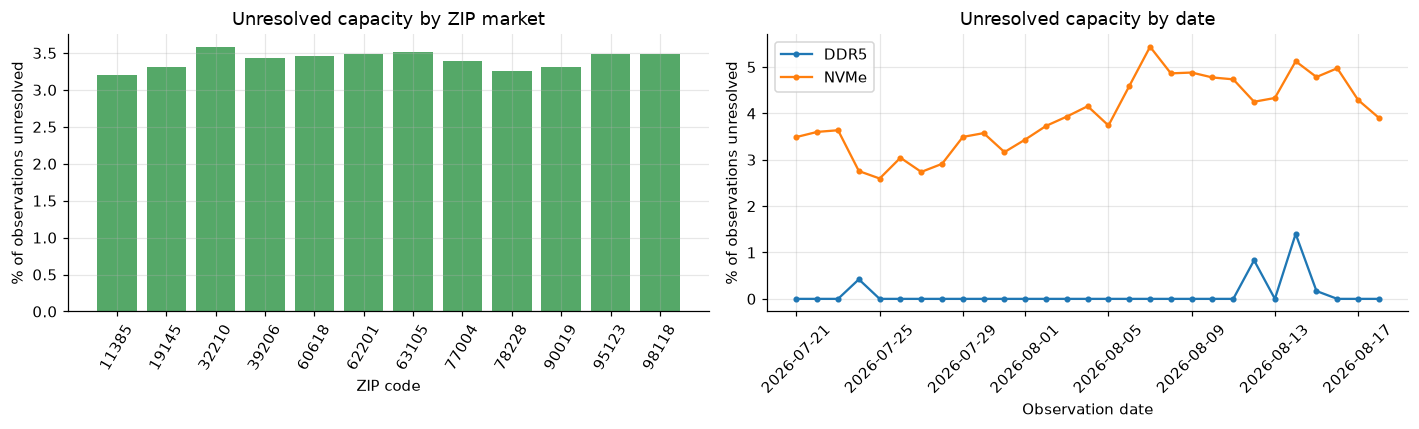

In [20]:
# Does unresolved capacity follow a pattern (category, ZIP, date)?
by_cat = df.groupby("category", observed=True)["is_unresolved"].agg(["sum", "mean", "size"])
by_cat["mean"] *= 100
print("By category (mean = % unresolved):"); display(by_cat)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
zip_rate = 100 * df.groupby("geography_id")["is_unresolved"].mean()
axes[0].bar(zip_rate.index.astype(str), zip_rate.values, color="#55A868")
axes[0].set_title("Unresolved capacity by ZIP market")
axes[0].set_xlabel("ZIP code"); axes[0].set_ylabel("% of observations unresolved")
axes[0].tick_params(axis="x", rotation=60)

for cat, g in df.groupby("category", observed=True):
    r = 100 * g.groupby("observed_date")["is_unresolved"].mean()
    axes[1].plot(r.index, r.values, marker="o", ms=3, label=cat)
axes[1].set_title("Unresolved capacity by date")
axes[1].set_xlabel("Observation date"); axes[1].set_ylabel("% of observations unresolved")
axes[1].legend(); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [21]:
print("Titles with the most unresolved rows:")
(df[df["is_unresolved"]].groupby(["category", "product_name"], observed=True).size()
   .rename("n_unresolved").sort_values(ascending=False).head(15).to_frame())

Titles with the most unresolved rows:


n_unresolved
category product_name                                                                                            
NVMe     SIX NVME M.2 SSD PCIe 4.0-1TB m.2 2280 ssd, Read UP to 7350MB/s 1TB for Gaming PS5 Memo...           348
         Ediloca SSD 2TB NVMe PCIe 5.0x4, Up to 14,000MB/s Read, 10,000MB/s Write, 2TB SSD with ...           339
         SUNEAST Black Series 2TB SSD Gen5, PCIe 5.0x4 NVMe M.2 2280 | Up to 14,800 MB/s Read, 1...           280
         KingSpec NX Series 512GB Gen3x4 NVMe M.2 SSD, Up to 3500MB/s, 3D NAND Flash M2 2280 Int...           259
         Kingston NV3 1TB M.2 2280 NVMe SSD | PCIe 4.0 Gen 4x4 | Up to 6000 MB/s | SNV3S/1000G |...           239
         OEM New WD PC SN730 NVMe SSD 512GB Capacity Read speeds up to 3,400MB/s, Write Speed up...           237
         Crucial T500 1TB PCIe Gen4 NVMe Gaming PS5 SSD with Heatsink, Up to 7,300MB/s, TLC NAND...           224
         Samsung 970 PRO NVMe Series 512GB M.2 PCI-Express 3.0 x 4 Solid State Drive (V-NAND)                 214
         NVMe SSD Internal Solid State Drive                                                                  183
         Intel Optane Memory H10 32GB with SSD Solid State Storage 512GB HBRPEKNX0202A M.2 2280 ...           179
         Ediloca 1TB PS5 SSD with Heatsink PCIe Gen4 NVMe M.2 Gaming SSD, 7400MB/s Read, 1GB DRA...           154
         XPG GAMMIX S70 BLADE - PCIe Gen4 Solid State Drive (SSD) - Up to 7400/6800 MB/s Read/Wr...           151
         KingSpec NX Series 1TB Gen3x4 NVMe M.2 SSD, Up to 3500MB/s, 3D NAND Flash M2 2280 Inter...           144
         Synology SNV5420-400G M.2 NVMe SSD 400G                                                              141
         NVMe SSD, M.2 NVMe SSD with Heatsink, Up to 2300MB/s, 256GB Gen3x4 Internal Solid State...           139

**Handling plan for missing values** (`TODO (team)`: confirm after reading the outputs above):

- `normalized_price_amount` is blank **only** where capacity is unresolved → this is *structural* missingness, not random. We do not impute it.
- Analyses that need price per GB/TB (Q1, Q5) exclude unresolved rows, and report how many rows that removes (via `analysis_view`).
- Analyses that only need the listed price (Q2, Q3, Q4) keep unresolved rows, except the noise rows (`is_noise` = complete computers + complete NAS appliances).
- Sensitivity check: repeat the key result with and without unresolved rows (criterion D6).

### 3.2.5 Relationships

In [ ]:
# Capacity vs price (resolved rows only): median listed price per capacity tier.
res = df[~df["is_unresolved"] & ~df["is_noise"]].copy()
# Put every capacity on one scale (GB) so that 512 GB and 1 TB sit on the same axis (1 TB = 1,000 GB).
res["capacity_gb"] = np.where(res["quantity_unit"].astype(str) == "terabytes",
                              res["quantity_value"] * 1000.0, res["quantity_value"])
tier = (res.groupby(["category", "capacity_gb"], observed=True)
           .agg(n_rows=("price_amount", "size"), median_price=("price_amount", "median"),
                median_norm_price=("normalized_price_amount", "median"))
           .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (cat, g) in zip(axes, tier.groupby("category", observed=True)):
    g = g[g["n_rows"] >= 30]
    ax.scatter(g["capacity_gb"], g["median_price"], s=np.sqrt(g["n_rows"]) * 3, alpha=0.7)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{cat}: median listed price by capacity tier (tiers with n >= 30)")
    ax.set_xlabel("Recorded capacity (GB, log scale; marker size ~ number of rows)")
    ax.set_ylabel("Median price_amount (USD, log scale)")
plt.tight_layout(); plt.show()
tier.sort_values(["category", "capacity_gb"])

In [ ]:
# Rank correlation between capacity (GB) and listed price, within each category.
from scipy.stats import spearmanr
rows = []
for cat, g in res.groupby("category", observed=True):
    if len(g) > 30 and g["capacity_gb"].nunique() > 1:
        rho, p = spearmanr(g["capacity_gb"], g["price_amount"])
        rows.append({"category": cat, "n": len(g), "spearman_rho": rho, "p_value": p})
pd.DataFrame(rows)

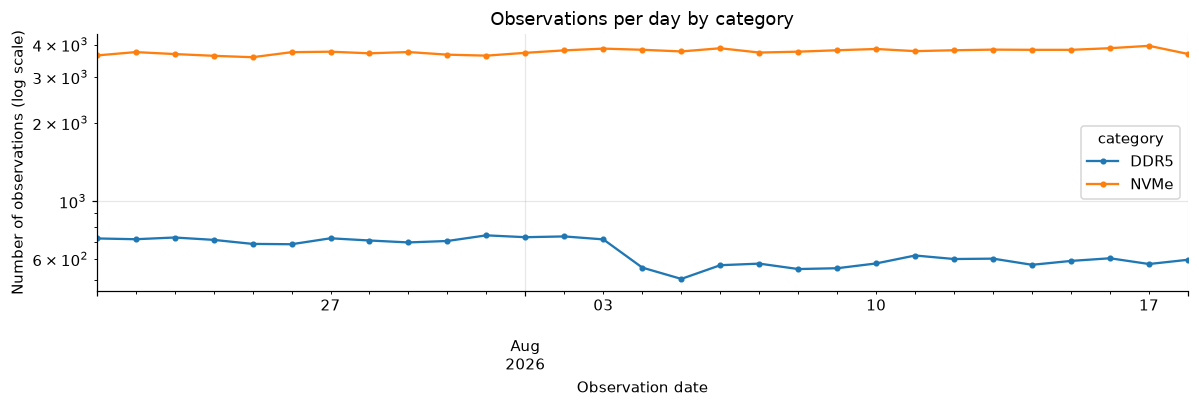

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
DDR5,29.0000,643.1034,73.6359,504.0000,577.0000,620.0000,715.0000,741.0000
NVMe,29.0000,"3,765.2759",88.5683,"3,583.0000","3,709.0000","3,763.0000","3,825.0000","3,963.0000"


In [24]:
# Volume per date and category: how many observations does each day contribute?
daily = df.groupby(["observed_date", "category"], observed=True).size().unstack("category")
ax = daily.plot(figsize=(11, 3.8), marker="o", ms=3, logy=True)
ax.set_title("Observations per day by category")
ax.set_xlabel("Observation date"); ax.set_ylabel("Number of observations (log scale)")
plt.tight_layout(); plt.show()
daily.describe().T

In [ ]:
# ZIP x category: median listed price (NOT adjusted for product mix, so only descriptive).
pd.pivot_table(df[~df["is_noise"]], index="geography_id", columns="category",
               values="price_amount", aggfunc="median", observed=True)

### 3.2.6 Preparation for Q1 (brand premium) — a temporary brand

`src/parse_titles.py` (Khải) will provide the real `brand`, `speed`, `kit_size` and `capacity` fields.
Until it is ready, the **first word of the title** is used only to explore how concentrated brands are. It is a placeholder, not a result.

In [26]:
tmp_brand = df["product_name"].astype(str).str.split().str[0].str.strip(",-").str.title()
df["brand_tmp"] = tmp_brand

for cat in ("DDR5", "NVMe"):
    g = df[df["category"] == cat]
    vc = g["brand_tmp"].value_counts()
    top = vc.head(12)
    print(f"===== {cat}: {vc.size} distinct first words; top 12 cover {100 * top.sum() / len(g):.1f}% of rows =====")
    display(top.to_frame("n_rows").assign(pct=lambda x: 100 * x["n_rows"] / len(g)))

===== DDR5: 31 distinct first words; top 12 cover 98.5% of rows =====


,n_rows,pct
brand_tmp,,
G.Skill,5945,31.8767
Corsair,3719,19.9410
Teamgroup,1917,10.2788
Crucial,1761,9.4424
Patriot,1261,6.7614
Lexar,845,4.5308
Pny,760,4.0751
Kingston,721,3.8660
A-Tech,621,3.3298


===== NVMe: 122 distinct first words; top 12 cover 45.9% of rows =====


,n_rows,pct
brand_tmp,,
Samsung,7802,7.1451
Fikwot,5029,4.6056
Crucial,4968,4.5497
Western,4821,4.4151
Kingspec,4559,4.1752
Fanxiang,4498,4.1193
Wd_Black,3762,3.4453
Ediloca,3224,2.9526
Bestoss,3112,2.8500


In [ ]:
# Do the main brands exist in both capacity tiers (needed to control for capacity in Q1)?
res = df[~df["is_unresolved"] & ~df["is_noise"]].copy()
res["capacity_gb"] = np.where(res["quantity_unit"].astype(str) == "terabytes",
                              res["quantity_value"] * 1000.0, res["quantity_value"])
top_brands = {cat: res[res["category"] == cat]["brand_tmp"].value_counts().head(8).index for cat in ("DDR5", "NVMe")}
for cat in ("DDR5", "NVMe"):
    g = res[(res["category"] == cat) & res["brand_tmp"].isin(top_brands[cat])]
    print(f"===== {cat}: rows by top brand x capacity tier (GB) =====")
    display(pd.crosstab(g["brand_tmp"], g["capacity_gb"]))

### 3.2.7 Preparation for Q2 (same product over time) — cohort structure

Q2 follows the **same product in the same ZIP** (`category × product_name × geography_id`) over time.
Before choosing the method we need to know: (a) how many rows a cohort has per day (titles are not unique SKUs), (b) how many days each cohort is observed, and (c) how many cohorts appear in **both** the first-7-day and last-7-day windows.

In [28]:
KEYS = ["category", "product_name", "geography_id"]

# (a) rows per cohort per day
cell = df.groupby(KEYS + ["observed_date"], observed=True).size().rename("rows_per_cohort_day")
print("Rows per (cohort, day):")
display(cell.groupby("category", observed=True).describe())
print("Distribution of rows_per_cohort_day (share of cohort-days):")
display((cell.value_counts(normalize=True).sort_index().head(8) * 100).to_frame("pct"))

Rows per (cohort, day):


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
DDR5,"18,650.0000",1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
NVMe,"108,879.0000",1.0029,0.0536,1.0000,1.0000,1.0000,1.0000,2.0000


Distribution of rows_per_cohort_day (share of cohort-days):


,pct
rows_per_cohort_day,
1,99.7538
2,0.2462


Number of cohorts: 11039


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
DDR5,"1,849.0000",10.0865,9.2632,1.0000,2.0000,6.0000,15.0000,29.0000
NVMe,"9,190.0000",11.8476,9.4718,1.0000,3.0000,9.0000,19.0000,29.0000


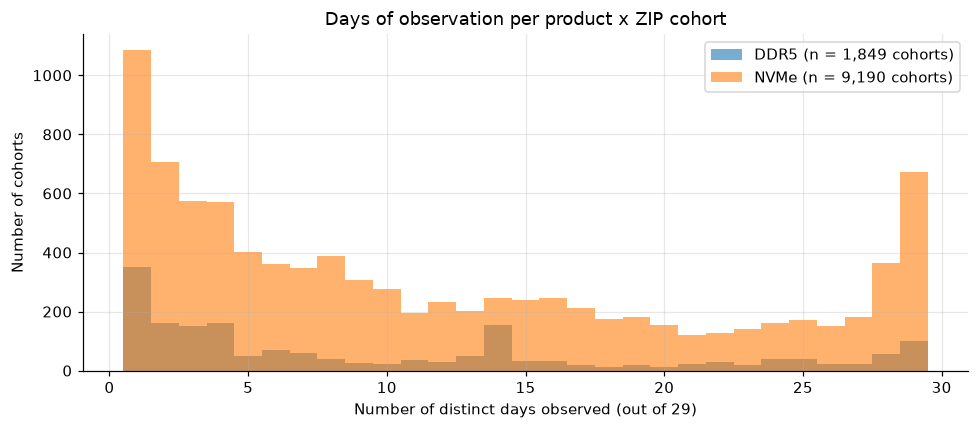

In [29]:
# (b) number of distinct days each cohort is observed
cohort = (df.groupby(KEYS, observed=True)
            .agg(n_rows=("price_amount", "size"), n_days=("observed_date", "nunique")))
print("Number of cohorts:", len(cohort))
display(cohort.groupby("category", observed=True)["n_days"].describe())

fig, ax = plt.subplots(figsize=(9, 4))
for cat, g in cohort.groupby("category", observed=True):
    ax.hist(g["n_days"], bins=np.arange(0.5, 30.5, 1), alpha=0.6, label=f"{cat} (n = {len(g):,} cohorts)")
ax.set_title("Days of observation per product x ZIP cohort")
ax.set_xlabel("Number of distinct days observed (out of 29)"); ax.set_ylabel("Number of cohorts")
ax.legend(); plt.tight_layout(); plt.show()

In [30]:
# (c) coverage of the first and last 7-day windows
FIRST = ("2026-07-21", "2026-07-27")
LAST = ("2026-08-12", "2026-08-18")

def days_in_window(frame, start, end, name):
    sub = frame[frame["observed_date"].between(start, end)]
    return sub.groupby(KEYS, observed=True)["observed_date"].nunique().rename(name)

cov = pd.concat([days_in_window(df, *FIRST, "days_first7"),
                 days_in_window(df, *LAST, "days_last7")], axis=1).fillna(0)

rows = []
for min_days in (1, 3, 5):
    ok = (cov["days_first7"] >= min_days) & (cov["days_last7"] >= min_days)
    by_cat = ok.groupby(level="category", observed=True).agg(["sum", "size"])
    for cat, r in by_cat.iterrows():
        rows.append({"min days in each window": min_days, "category": cat,
                     "cohorts usable for Q2": int(r["sum"]), "cohorts total (seen in either window)": int(r["size"])})
pd.DataFrame(rows)

,min days in each window,category,cohorts usable for Q2,cohorts total (seen in either window)
0,1,DDR5,555,1555
1,1,NVMe,3325,8141
2,3,DDR5,387,1555
3,3,NVMe,2283,8141
4,5,DDR5,235,1555
5,5,NVMe,1551,8141


`TODO (team)`: use the three tables above to decide for Q2 (a) how to collapse several rows of one cohort-day (median per day is the natural choice), (b) the minimum number of days required in each window, and (c) whether the 5/7/10-day windows of the sensitivity check still have enough cohorts. Record the decision in `DECISIONS.md`.

### 3.2.8 Summary of the exploration

`TODO (team)`: write this section yourselves after reading the outputs (3–5 key observations, serious data quality issues, preprocessing plan, patterns that lead to questions). Suggested structure:

1. **Key observations** (3–5, with numbers from the tables above).
2. **Serious data quality issues** (unresolved capacity, category noise, title ≠ SKU, DDR5 vs NVMe not comparable).
3. **Preprocessing plan** (flags instead of deletion; `analysis_view` for per-unit questions; row counts logged).
4. **Patterns that lead to the six questions** (Q1–Q6).

In [31]:
# Row-count log of every data-changing step in this notebook (required by the brief).
log.table()

,step,rows_before,rows_after,rows_removed,reason
0,"load raw CSV, keep 10 of 16 columns",127843,127843,0,"6 constant/redundant columns removed (columns, not rows)"
1,add flag columns,127843,127843,0,"category, is_unresolved, is_system_noise, price_per_unit_recomputed (no rows removed)"


In [32]:
# Save the flagged table for the other notebooks (data/processed/ is not committed to Git).
out = save_processed(df.drop(columns=["brand_tmp"]), "flagged")
print("Saved:", out, "-", len(df), "rows")

Saved: D:\NGUYEN\Documents\Lập trình KHDL\Project\code\DDR5-and-NVMe-Prices-Analysis\data\processed\flagged.pkl - 127843 rows
